# CT4101 Machine Learning 

## Machine Learning Portfolio: Predicting 30-Day Hospital Readmission in Patients with Diabetes Using Machine Learning

## 7. Conclusion

### Student Name: Faith Greene

### Student ID: 26256593


A results table to compare the models is below.

In [58]:
dummy_results["Dummy Classifier"] = dummy_results["Score"]
lr_results["Logistic Regression"] = lr_results["Score"]
dt_results["Decision Tree"] = dt_results["Score"]
rf_results["Random Forest"] = rf_results["Score"]

# Combine the results
comparison_results = pd.DataFrame({
    "Metric": dt_results["Metric"],
    "Dummy Classifier": dummy_results["Dummy Classifier"],
    "Logistic Regression": lr_results["Logistic Regression"],
    "Decision Tree": dt_results["Decision Tree"],
    "Random Forest": rf_results["Random Forest"]
})

# Display results
display(comparison_results.round(3))

,Metric,Dummy Classifier,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.89,0.889,0.889,0.889
1,Precision,0.00,0.407,0.417,0.231
2,Recall,0.00,0.007,0.003,0.002
3,F1-score,0.00,0.013,0.006,0.004
4,ROC-AUC,0.50,0.633,0.649,0.620


An ROC curve shows how well the models distinguish between patients who were readmitted and those who weren't.

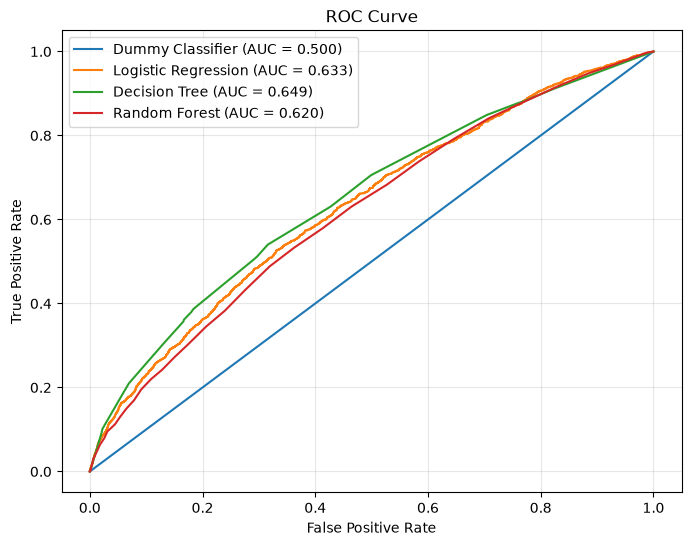

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Model predictions
models = {
    "Dummy Classifier": y_prob_baseline,
    "Logistic Regression": y_prob_lr,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf
}

plt.figure(figsize=(8, 6))

# Plot ROC curve for each model
for name, probabilities in models.items():

    FP, TP, thresholds = roc_curve(y_val, probabilities)

    AUC = roc_auc_score(y_val, probabilities)

    plt.plot(FP, TP, label=f"{name} (AUC = {AUC:.3f})")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The decision tree achieved the highest ROC-AUC score of 0.649, followed by logistic regression, then random forest and then the dummy classifier.

#### Error Analysis

As the validation ROC-AUC is largest for the decision tree, I will asses the errors for the decision tree as this is the model that performs best.

In [62]:
from sklearn.metrics import confusion_matrix

# confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val, y_pred_dt, labels=[0, 1]
).ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

# false negative and false positive rates
fn_rate = fn / (fn + tp) * 100
fp_rate = fp / (fp + tn) * 100

print("FN Rate:", round(fn_rate, 2), "%")
print("FP Rate:", round(fp_rate, 2), "%")

TN: 13453
FP: 7
FN: 1667
TP: 5
FN Rate: 99.7 %
FP Rate: 0.05 %


The examination of the confusion matrix revealed significant limitations in model performance.

The model correctly identified 13,453 patients who were not readmitted but only identified 5 patients who were readmitted. It produced 1,667 false negatives, resulting in a false negative rate of 99.7%. This means that the model failed to identify almost all patients who experienced readmission. The false positive rate was very low at 0.05%, indicating that the model rarely incorrectly predicted readmission.

This may be influenced by the imbalance between the two classes.

#### Conclusion

Based on the validation results, the Decision Tree was the best-performing model, achieving the highest ROC-AUC score of 0.649. Logistic Regression achieved an ROC-AUC of 0.633, Random Forest achieved 0.620. All three machine learning models performed better than the Dummy Classifier. However, the overall predictive performance was not very high.

Although the decision tree model correctly classified 13,453 patients who were not readmitted, it only identified 5 of the 1,672 patients who were readmitted. This resulted in a false negative rate of 99.70%, meaning that almost all actual readmissions were missed. 

There are many limitations to the current models. The imbalance between the readmission classes may have affected the models' ability to identify patients who were readmitted. The models also used relatively simple hyperparameter settings.

Next steps will include investigating ways to address class imbalance. Hyperparameter tuning could also help improve model performance. 

#### Assistance Declaration

AI was used for guidance on debugging in this work. All other work, code, analysis, results and final decisions were completed individually.